## Colab 환경에서 실행 시 환경 설정

In [ ]:
# 구글 드라이브의 폴더와 구글 코랩 폴더 연결
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# 현재 경로 확인
!pwd

In [ ]:
# drive/MyDrive/Colab Notebooks 경로로 변경
%cd drive/MyDrive/'Colab Notebooks'

#### 코랩에서 한국어 표시하기

In [ ]:
!pip install koreanize-matplotlib

In [103]:
import koreanize_matplotlib

# 🔖 자연어 처리 기초2

<a id="lecture_index"></a>
## 수업 목차 

[1. 복습](#one)<br>
- 텍스트 데이터의 특징 
- 텍스트 데이터의 처리 과정 
- 규칙기반 자연어 처리 
- 통계기반 자연어 처리 

[2. 통계기반 자연어 처리](#two)<br>
- Bag of Words
- TF-IDF

[3. 분산표현과 신경망](#three)<br>
- 워드 임베딩의 개념 
- Word2Vec

[4. 순환 신경망](#four)<br>
- RNN 모델 특징 
- RNN 구조 수식 및 시각화 
- PyTorch로 구현하기


## <a id='one'>1️⃣ 복습</a><br>

<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

### 🧩 Quiz 1

## <a id='two'>2️⃣ 통계기반 자연어 처리</a><br>

<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

> 통계 기반 NLP는 코퍼스를 통해 단어의 빈도, 동시 발생 빈도 등을 기반으로 처리를 함 <br> 
> 💡 통계적 언어 모델의 핵심 아이디어: 단어의 의미는 주변 단어로 알 수 있다 

## 텍스트 데이터 단위 

<img src="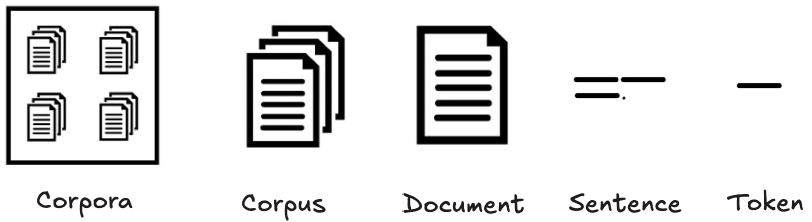
" width="1100" height="350"/>

1. Corpora <br>
: 여러개의 Corpus <br>
예) 다국어 번역 모델 Corpora [영어-한국어 번역 corpus, 한국어-일본어 번역 corpus, 등...]

2. Corpus <br>
: 자연어 문서들의 집합. 모델 학습용으로 수집된 텍스트 데이터 전체. <br>
예) 뉴스 기사 모음, 나무위키 데이터 모음, SNS 글 모음 <br>
⚠️ 단순히 텍스트의 모음이 아니라 품사 태그가 붙거나 텍스트에 라벨이 붙은 데이터도 전부 corpus라 부름 <br>
(raw corpus, annotated corpus, cleaned corpus 등..)

3. Document <br>
: Corpus를 구성하는 개별 문서. <br>
예) 뉴스 기사 하나, 나무위키 검색으로 보이는 페이지 하나, SNS 게시글 하나 <br>

4. Sentence <br> 
: Corpus를 구성하는 개별 문장. <br> 
  분석 목적에 따라 텍스트를 Document 대신 Sentence 단위로 지정하기도 함 <br> 
예) 두 문장의 유사도 분석이 필요한 경우

5. Token <br>
: 문장에서 의미 있는 최소 단위의 단어. <br>
예) "나는 비빔 인간입니다" -> 나, 비빔, 인간, 입니다 또는 나는, 비빔, 인간입니다 등...  <br>
⚠️ 토큰화는 목적에 따라 달라질 수 있음 

## Bag of Words 

> 문장을 단어의 집합(가방)으로 보고, 순서와 상관 없이 등장 횟수만 고려하는 방식 <br>
> 단어 목록을 만들고 이를 기반으로 문장을 벡터화 하는 과정까지 포함한다

### ✅ 특징 

#### ① 간단하고 빠른 처리가 가능 
#### ② 희소(sparse) 벡터가 만들어짐 
#### ③ 문맥을 고려하지 않음

In [63]:
from konlpy.tag import Mecab
from sklearn.feature_extraction.text import CountVectorizer

In [64]:
corpus1 = ["나는 비빔 인간입니다.", "나는 비빔밥을 좋아합니다.", "저는 파스타를 좋아합니다."]
corpus2 = ["오늘 날씨 매우 매우 좋다", "내일은 비 온다", "나는 날씨가 싫다"]

In [65]:
mecab = Mecab()

def mecab_tokenizer(text):
    return mecab.morphs(text)

def custom_preprocessor(text):
    return text.replace('.', '')

korean_stopwords = ['는', '을', '를', '이', '가', '저는', '나는', '입니다', '합니다']

# 처리 순서 1. preprocessor 2. tokenizer 3. 불용어 처리 4. ngram 적용 5. 단어 빈도 계산 및 제거 6. 벡터 생성
vectorizer = CountVectorizer(tokenizer=mecab_tokenizer,  # 사용자 지정 토크나이저 
                             stop_words=korean_stopwords, # 불용어 지정 
                             ngram_range=(1,2),  # n개 부터 m개 까지의 단어 묶음으로 만들기 -> 단어 사이의 문맥과 조합된 의미 반영을 위해
                             max_features=20, # 가장 많이 등장한 단어 개수 지정  
                             min_df=1, # 최소 1개 문서에 등장한 단어만 사용 
                             max_df=0.8, # n% 이상 문서에 등장하면 제외 
                             lowercase=False, # 한글에는 적용 X 
                             preprocessor=custom_preprocessor,
                             token_pattern='(?u)\\b\\w\\w+\\b') # 여기에 쓰인 정규식 패턴으로 토큰을 분리 (기본값)
                             # (?u) -> 유니코드 모드(한글을 포함한 문자도 글자로 인식 할 수 있게 해줌)
                             # \b -> 띄어쓰기를 기준으로 단어의 시작 혹은 끝으로 인식 
                             # \w -> 글자 하나 (한글, 영어, 숫자, 밑줄 중 하나)
                             # \w\w+ -> 두 글자 이상 

In [66]:
corpus = corpus1+corpus2
x = vectorizer.fit_transform(corpus)

/Users/jihyeokjeong/.anyenv/envs/pyenv/versions/human_lecture/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/Users/jihyeokjeong/.anyenv/envs/pyenv/versions/human_lecture/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['나', '저'] not in stop_words.
  warnings.warn(


In [67]:
x.toarray()

array([[1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1],
       [0, 1, 1, 2, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0],
       [1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

Corpus와 토크나이저만 입력을 받으면 벡터와 단어 사전을 출력할 수 있도록 함수 구현

In [68]:
# 내부적으로는 for문 처럼 하나하나 순회해서 작동함. 단, C 기반으로 최적화 돼어 있어 python으로 for 문 하는 것 보단 빠름 
def bag_of_words(corpus, tokenizer=None): 
    vectorizer = CountVectorizer(tokenizer=tokenizer)  
    vectors = vectorizer.fit_transform(corpus)
    return vectors.toarray(), vectorizer.vocabulary_ # scikit-learn에서 언더바는 학습 이후 생기는 속성 (fit 또는 fit_transform 연산으로 만들어지는 속성)

In [69]:
bag_of_words(corpus1, mecab_tokenizer)

(array([[1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1],
        [1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1]]),
 {'나': 1,
  '는': 2,
  '비빔': 4,
  '인간': 8,
  '입니다': 9,
  '.': 0,
  '비빔밥': 5,
  '을': 7,
  '좋': 11,
  '아': 6,
  '합니다': 13,
  '저': 10,
  '파스타': 12,
  '를': 3})

In [72]:
from konlpy.tag import Mecab
from itertools import chain # iterable 객체를 하나로 이어주는 함수 
import numpy as np 

mecab = Mecab()

def bag_of_words2(corpus, tokenizer):
    token_list = [tokenizer(sent) for sent in corpus]
    unq_tokens = set(chain.from_iterable(token_list)) 
    word_dict = {word: idx for idx, word in enumerate(unq_tokens)}
    bow_vectors = []
    for tokens in token_list: 
        vec = np.zeros(len(unq_tokens))
        for word in tokens:
            if word in word_dict:
                vec[word_dict[word]] += 1 
        bow_vectors.append(vec)
    return bow_vectors, word_dict

def bag_of_words3(corpus, tokenizer):
    token_list = [tokenizer(sent) for sent in corpus]
    unq_tokens = sum(token_list, [])
    word_dict = {word: idx for idx, word in enumerate(unq_tokens)}
    bow_vectors = []
    for tokens in token_list: 
        vec = np.zeros(len(unq_tokens))
        for word in tokens:
            if word in word_dict:
                vec[word_dict[word]] += 1 
        bow_vectors.append(vec)
    return bow_vectors, word_dict

def bag_of_words4(corpus, tokenizer):
    token_list = [tokenizer(sent) for sent in corpus]
    unq_tokens = [token for tokens in token_list for token in tokens]
    word_dict = {word: idx for idx, word in enumerate(unq_tokens)}
    bow_vectors = []
    for tokens in token_list: 
        vec = np.zeros(len(unq_tokens))
        for word in tokens:
            if word in word_dict:
                vec[word_dict[word]] += 1 
        bow_vectors.append(vec)
    return bow_vectors, word_dict

In [73]:
vec , word_dit = bag_of_words2(corpus, mecab_tokenizer)

#### ✅ Lazy Evaluation vs Eager Evaluation 

- Lazy Evaluation: 값을 지금 바로 계산하지 않고, 필요할 때마다 한 개씩 계산해서 리턴하는 방식 <br> 
- Eager Evaluation: 코드가 실행되면 바로 값을 만들어서 전체를 메모리에 저장하여 연산하는 방식  

In [74]:
# Eager 
squares = [x**2 for x in range(5)]

In [75]:
# Lazy Evaluation
squares = iter(x**2 for x in range(5))

In [ ]:
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

def benchmark(functions, *args, **kwargs):
    results = []
    for func in functions:
        print(f"{func.__name__} 실행 중...")

        # 메모리 추적 시작
        tracemalloc.start()
        start_time = time.time()

        result = func(*args, **kwargs)

        elapsed_time = time.time() - start_time
        current, peak = tracemalloc.get_traced_memory() # 현재 메모리 사용량 (바이트), 추적 시작 이후 최대 메모리 사용량 
        tracemalloc.stop()

        results.append({
            'name': func.__name__,
            'time_sec': round(elapsed_time, 3),
            'memory_mb': round(peak / 1024 / 2024, 3),
            'result': result 
        })

    return results

In [79]:
from datasets import load_dataset

dataset = load_dataset('nsmc', trust_remote_code=True) # naver sentiment movie corpus

In [80]:
result = benchmark([bag_of_words, bag_of_words2, bag_of_words3, bag_of_words4], dataset['train'][:10000]['document'], mecab_tokenizer)

bag_of_words 실행 중...
bag_of_words2 실행 중...
bag_of_words3 실행 중...
bag_of_words4 실행 중...


In [85]:
# result[0]['name'], result[0]['time_sec'], result[0]['memory_mb']
# result[1]['name'], result[1]['time_sec'], result[1]['memory_mb']
# result[2]['name'], result[2]['time_sec'], result[2]['memory_mb']
result[3]['name'], result[3]['time_sec'], result[3]['memory_mb']

('bag_of_words4', 3.659, 7218.134)

### 네이버 영화 리뷰 긍정/부정 분석 

In [22]:
from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from konlpy.tag import Mecab
import re 

# 1. 데이터 불러오기
dataset = load_dataset('nsmc', trust_remote_code=True) 
train_dataset = dataset['train']
test_dataset = dataset['test']

x_train = train_dataset['document']
y_train = train_dataset['label']

x_test = test_dataset['document']
y_test = test_dataset['label']

In [23]:
len(x_train), len(x_test)

(150000, 50000)

In [36]:
# 2. 토큰화 및 전처리 
mecab = Mecab()
def mecab_tokenizer(text):
    return mecab.morphs(text)

def custom_preprocessor(text):
    # 한글, 공백 남기고 제거 
    text = re.sub(r"[^가-힣\s]", "", text)
    # 반복 문자 축약 (정규화)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    
    return text.strip()

stopwords = ['은', '는', '이', '가', '을', '를', '에', '의', '도', '으로', '와', '한', '하', '고']

# 3. BoW 벡터화 
vectorizer = CountVectorizer(tokenizer=mecab_tokenizer,  
                             stop_words=stopwords,
                             ngram_range=(1,2), 
                             max_features=5000, # 데이터 크기, 메모리, 성능의 균형을 잡는 지점으로 결정 
                             min_df=1, 
                             max_df=0.9,  
                             lowercase=False,
                             preprocessor=custom_preprocessor)

X_train = vectorizer.fit_transform(x_train)
X_test = vectorizer.fit_transform(x_test)

/Users/jihyeokjeong/.anyenv/envs/pyenv/versions/human_lecture/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [37]:
model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)

LogisticRegression(max_iter=500)

In [ ]:
model2 = RandomForestClassifier(n_estimators=100)
model2.fit(X_train, y_train)

In [38]:
y_pred = model.predict(X_test)
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.51      0.55      0.53     23006
           1       0.59      0.55      0.57     26994

    accuracy                           0.55     50000
   macro avg       0.55      0.55      0.55     50000
weighted avg       0.56      0.55      0.55     50000



### TF-IDF

> Term Frequency - Inverse Document Frequency의 약자로, <br> 
> 한 문서 안에서 단어가 몇번 나왔는지, 여러 문서 중 이 단어가 얼마나 희귀한지를 고려하여 데이터를 벡터화 하는 방법 <br> 
> 흔한 단어는 가중치를 낮게, 자주 등장하는 단어는 가중치를 높게 

✅ “자주 등장하지만 모든 문서에서 흔한 단어는 중요하지 않다.
드물게 등장하면서 특정 문서에 많이 나타나는 단어가 진짜 중요하다!”

<img src="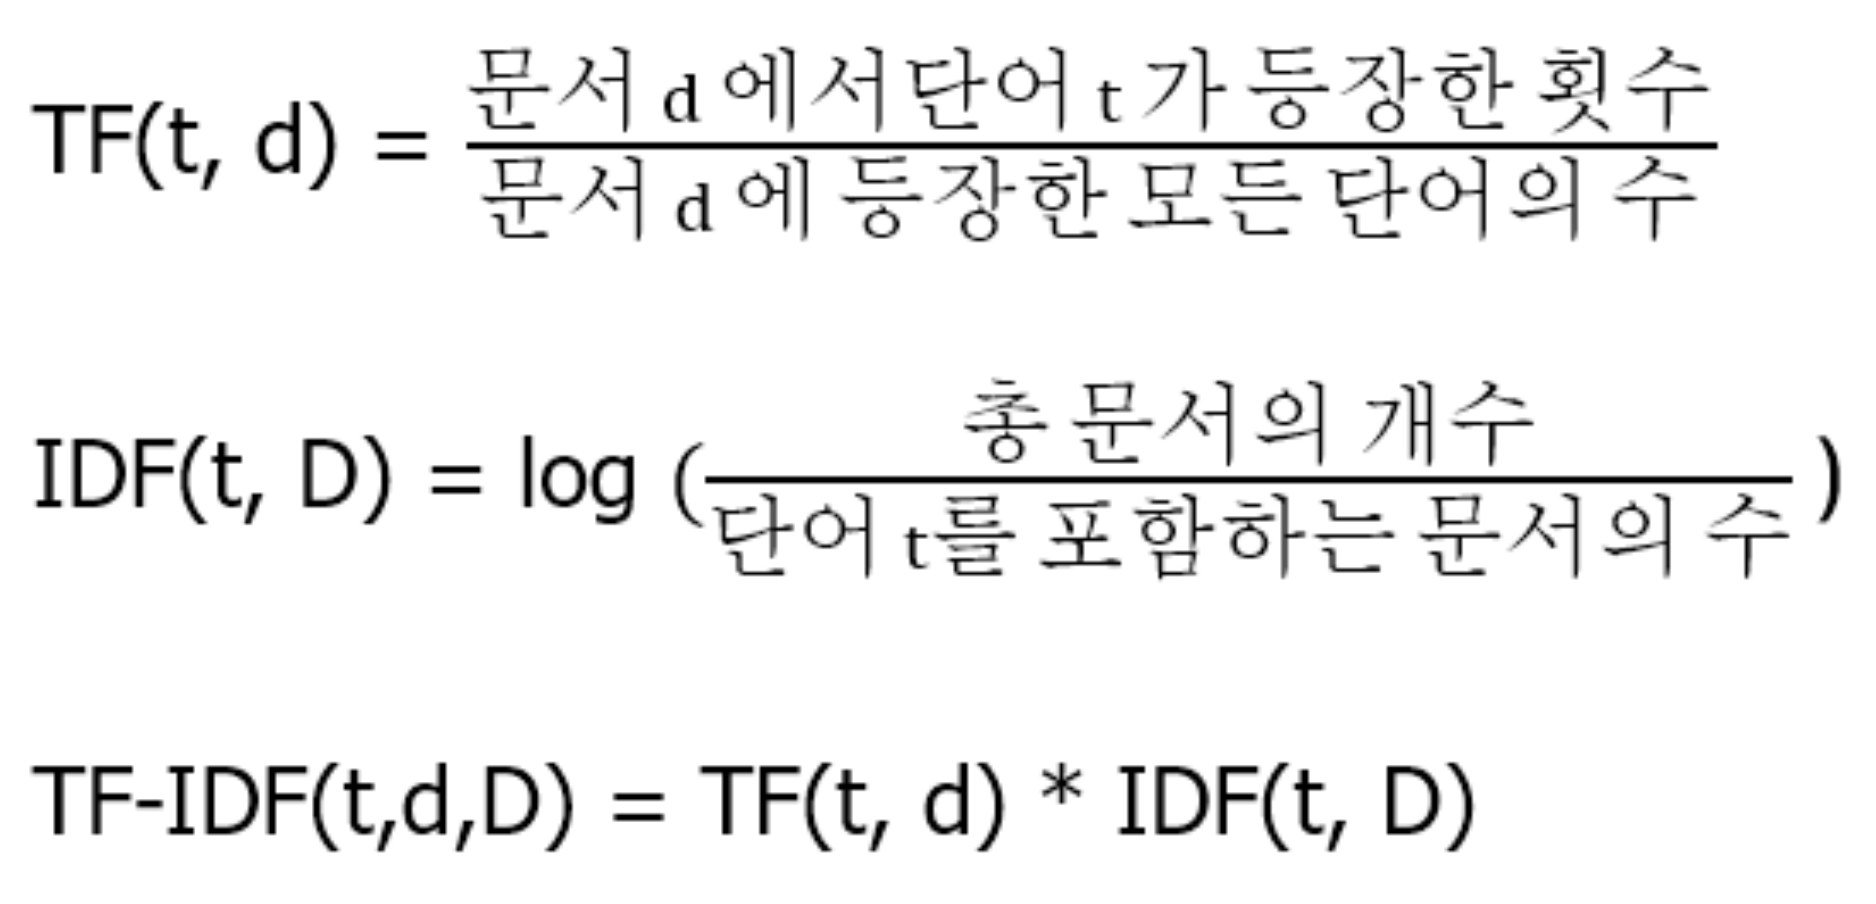
" width="680" height="350"/>

🛠️ log를 취하는 이유는 드물게 나오는 값의 크기가 너무 커지는 것을 방지하기 위해서 <br>
그리고 정보 이론에 따르면 어떤 단어가 드물게 등장할수록, 그 단어가 더 많은 정보를 담고 있다는 의미 이고, 
정보량은 아래와 같이 정의됨 

$$
\text{Information}(t) = -\log(P(t))
$$

출처: https://yeong-jin-data-blog.tistory.com/entry/TF-IDF-Term-Frequency-Inverse-Document-Frequency

### ✅ 특징 

#### ① 단순히 단어의 빈도 뿐만 아니라 전체 문서에서 얼마나 희귀한지도 반영함 <br>
 -> 정보량에 높은 가중치를 줌 (the, a, 은, 는, 이, 가 같이 빈번한 단어는 중요도를 낮게 봄)
#### ② 단어의 등장 위치는 고려하지 않음  
#### ③ 희소(sparse) 벡터가 만들어짐 

In [39]:
import math
from konlpy.tag import Mecab
from collections import Counter, defaultdict
import pandas as pd

# 1. 간단한 문서 코퍼스
corpus = [
    "나는 밥을 먹었다",
    "너는 김치를 좋아한다",
    "밥과 김치를 먹고 산책했다"
]

# 2. 형태소 분석
mecab = Mecab()
tokenized_corpus = [mecab.morphs(doc) for doc in corpus]

# 3. 불용어 제거
stopwords = set(["은", "는", "이", "가", "을", "를", "에", "의", "도", "으로", "와", "한", "하", "고"])
processed_corpus = [[w for w in doc if w not in stopwords] for doc in tokenized_corpus]

# 4. TF 계산
tf_list = []
for doc in processed_corpus:
    term_freq = Counter(doc)
    total = len(doc)
    tf = {term: freq / total for term, freq in term_freq.items()}
    tf_list.append(tf)

# 5. IDF 계산
doc_count = len(processed_corpus)
df = defaultdict(int) # 없는 키의 기본 값을 0으로 설정한 딕셔너리 
for doc in processed_corpus:
    for term in set(doc):
        df[term] += 1

idf = {term: math.log((doc_count / (df[term] + 1)) + 1) for term in df}

# 6. TF-IDF 계산
tfidf_list = []
for tf in tf_list:
    tfidf = {term: tf[term] * idf[term] for term in tf}
    tfidf_list.append(tfidf)

In [59]:
doc_count = len(processed_corpus)
df = defaultdict(int) # 없는 키의 기본 값을 0으로 설정한 딕셔너리 
for doc in processed_corpus:
    for term in set(doc):
        df[term] += 1

idf = {term: math.log((doc_count / (df[term] + 1)) + 1) for term in df}

In [ ]:
from konlpy.tag import Mecab
import re 
from sklearn.feature_extraction.text import TfidfVectorizer

mecab = Mecab()
def mecab_tokenizer(text):
    return mecab.morphs(text)

def custom_preprocessor(text):
    # 한글, 공백 남기고 제거 
    text = re.sub(r"[^가-힣\s]", "", text)
    # 반복 문자 축약 (정규화)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    
    return text.strip()

# 1. 예제 문서들 (Corpus)
documents = [
    "나는 오늘 영화관에 갔다",
    "오늘은 날씨가 정말 좋다",
    "나는 영화 보는 것을 좋아한다",
    "좋은 날씨에 산책을 했다"
]
 
stopwords = ['은', '는', '이', '가']

# 2. TF-IDF 벡터라이저 생성 및 학습
vectorizer = TfidfVectorizer(
    tokenizer=mecab_tokenizer,
    stop_words=stopwords,
    ngram_range=(1, 2),           # n개 부터 m개 까지의 단어 묶음으로 만들기 -> 단어 사이의 문맥과 조합된 의미 반영을 위해
    max_features=5000,            # 최대 특징 수 제한
    min_df=1,                     # 최소 문서 수 1 (즉, 한 번이라도 등장하면 포함)
    max_df=0.8,                   # 전체 문서 중 80% 이상 등장하는 단어는 제외
    lowercase=False,              # 대소문자 구분 안 함 (한글이니까 큰 의미 없음)
    preprocessor=custom_preprocessor
)
tfidf_matrix = vectorizer.fit_transform(documents)

In [51]:
# 3. 단어(특성) 목록 확인
vectorizer.get_feature_names_out()

array(['갔다', '것을', '나는', '날씨가', '날씨에', '보는', '산책을', '영화', '영화관에', '오늘',
       '오늘은', '정말', '좋다', '좋아한다', '좋은', '했다'], dtype=object)

In [52]:
len(vectorizer.get_feature_names_out())

16

In [54]:
# 4. TF-IDF 행렬 확인
tfidf_matrix.toarray()[0]

array([0.52547275, 0.        , 0.41428875, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.52547275, 0.52547275,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        ])

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from konlpy.tag import Mecab
import re

# 1. 예제 문서
documents = [
    "나는 오늘 너무너무 기분이 좋았다.",
    "오늘 날씨가 좋아서 산책을 했다.",
    "기분이 안 좋아서 집에만 있었다.",
    "정말 정말 재미있는 영화를 봤다!"
]

# 2. 형태소 분석기 객체 생성
mecab = Mecab()

# 3. 불용어 리스트
stopwords = ['을', '를', '이', '가']

# 4. 사용자 정의 tokenizer
def mecab_tokenizer(text):
    return [token for token in mecab.morphs(text) if token not in stopwords]

# 5. 사용자 정의 전처리 함수
def custom_preprocessor(text):
    # 특수 문자 제거 & 반복 문자 축소
    text = re.sub(r'[^가-힣\s]', '', text)  # 한글과 공백 제외 제거
    text = re.sub(r'(\w)\1{2,}', r'\1', text)  # 같은 글자 3번 이상 반복 축소
    return text.strip()

# 6. TF-IDF 벡터라이저 정의
vectorizer = TfidfVectorizer(
    tokenizer=mecab_tokenizer,
    stop_words=stopwords,
    ngram_range=(1, 2),           # 
    max_features=5000,            # 최대 특징 수 제한
    min_df=1,                     # 최소 문서 수 1 (즉, 한 번이라도 등장하면 포함)
    max_df=0.8,                   # 전체 문서 중 80% 이상 등장하는 단어는 제외
    lowercase=False,              # 대소문자 구분 안 함 (한글이니까 큰 의미 없음)
    preprocessor=custom_preprocessor
)

# 7. TF-IDF 행렬 생성
tfidf_matrix = vectorizer.fit_transform(documents)

In [ ]:
# 8. 단어 목록 출력
vectorizer.get_feature_names_out()

In [ ]:
# 9. TF-IDF 벡터 출력
tfidf_matrix.toarray()

### 🧩 Quiz 2

### NSMC 데이터셋을 활용한 감정 분류 모델 구현하기

1. 데이터는 Huggingface datasets 라이브러리를 사용하여 불러오세요.
2. 훈련 데이터와 검증 데이터를 8:2 비율로 나누세요.
3. TfidfVectorizer를 사용하여 문장을 벡터화하세요.
   (불용어 제거와 간단한 전처리 포함)
4. 분류기는 LogisticRegression을 사용하세요.
5. 예측 정확도를 출력하세요.

In [ ]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import re

# 1. 데이터 불러오기
dataset = load_dataset('nsmc')
texts = dataset['train']['document']
labels = dataset['train']['label']

# 2. 간단한 전처리
def preprocess(text):
    text = re.sub(r'[^가-힣\s]', '', text)
    return text.strip()

texts = [preprocess(t) for t in texts]

# 3. 데이터 분할
X_train, X_val, y_train, y_val = train_test_split(
    texts, labels, test_size=0.2, random_state=42)

# 4. TF-IDF 벡터화
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words=['영화', '진짜', '정말']
)
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)

# 5. 모델 훈련
model = LogisticRegression(max_iter=200)
model.fit(X_train_vec, y_train)

# 6. 예측 및 평가
y_pred = model.predict(X_val_vec)
accuracy = accuracy_score(y_val, y_pred)
print(f"검증 정확도: {accuracy:.4f}")

검증 정확도: 0.7778


## <a id='three'>3️⃣ 분산표현과 신경망</a><br>

<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

### 단어간의 유사성을 표현하는 방법

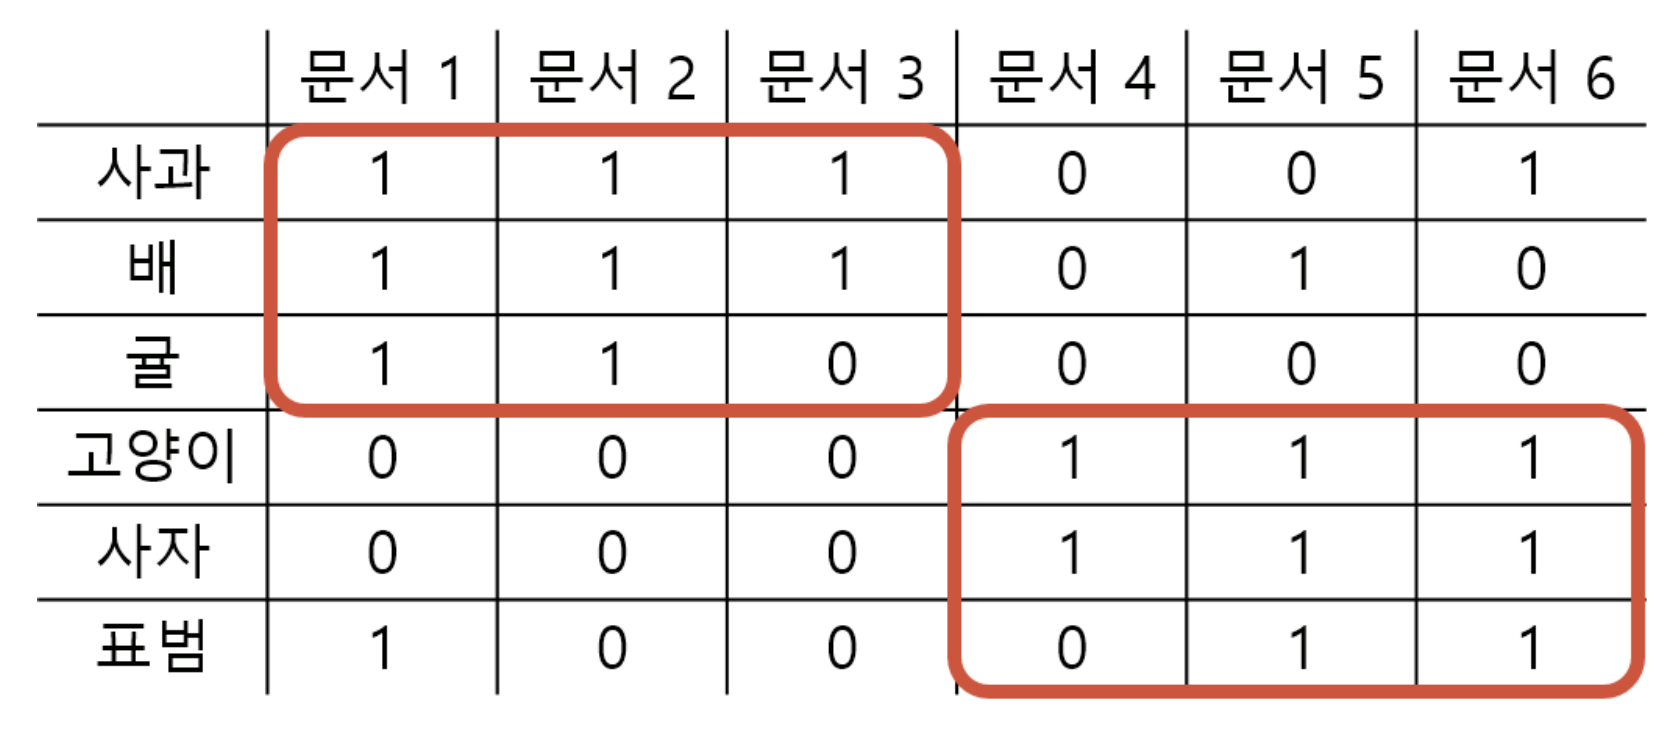

- 위 방식은 여러 문서가 있을 때 단어의 빈도를 통해 단어간의 유사성을 표현할 수 있음 
- 하지만, 단어의 유무로 벡터를 표현하기 때문에 벡터 자체가 단어의 의미를 내포하고 있지는 않음

<img src="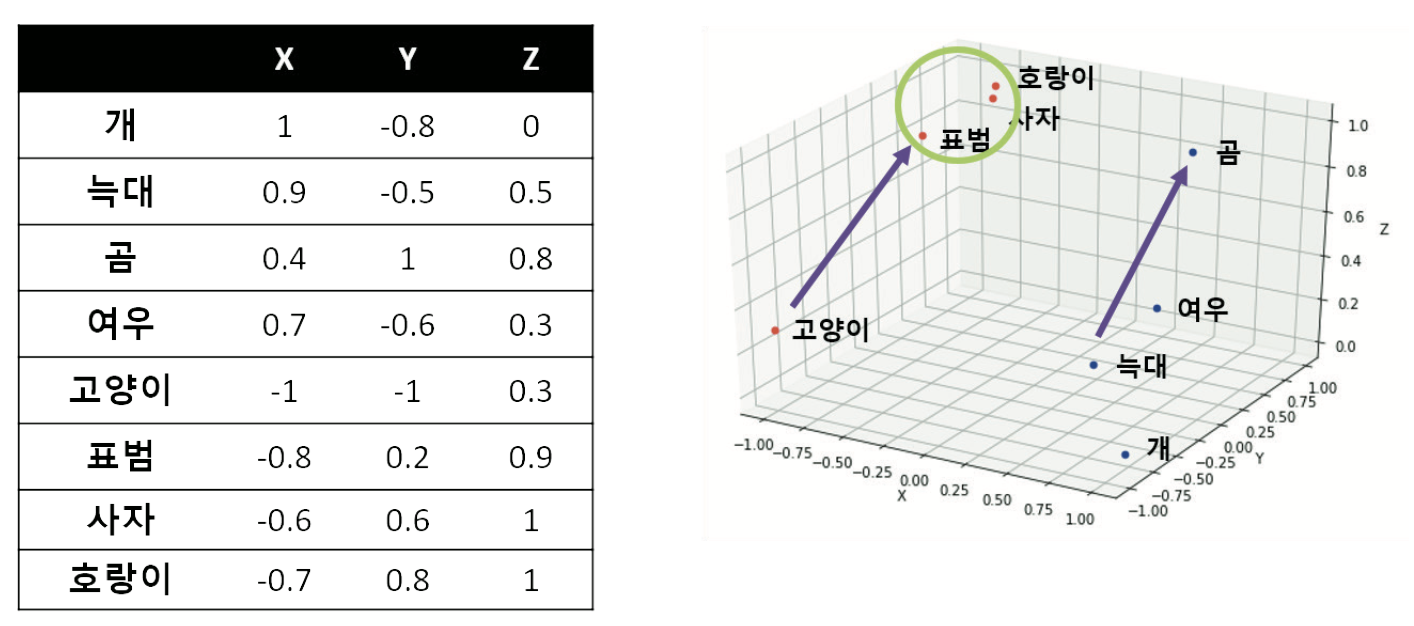
" width="750" height="400"/>

- 각 단어가 3차원 좌표 상의 한 점으로 표현 
- 좌표 상의 단순한 숫자(벡터)가 다른 단어와 함께 보면 즉, 문맥으로 보면 의미를 가짐 
- 비슷한 문맥에서 사용된 단어들일수록 비슷한 벡터 값을 가지게 됨

#### ✅ Word Embedding이란, 단어를 고정된 차원의 밀집 벡터로 변환하는 과정으로, 의미적으로 유사한 단어들이 벡터 공간 상에서 가깝도록 학습된다

👉 Embedding vector란, Word Embedding의 결과로 만들어진 단어 또는 토큰을 표현하는 벡터

### 🧐 어떻게 학습해야 Word Embedding을 만들 수 있는 걸까?

## Word2Vec

> 기존의 희소 벡터 방식의 한계를 극복하기 위해 만들어진 자연어 처리 기법 <br> 
> "비슷한 문맥에서 쓰이는 단어는 비슷한 의미를 가진다"는 분포 가설(Distributional Hypothesis)을 가정함 <br> 
> 주변 단어로 부터 중심 단어를 예측 하거나, 중심 단어로 부터 주변 단어를 예측하는 방식을 통해 단어를 의미 있는 벡터로 표현한다

<img src="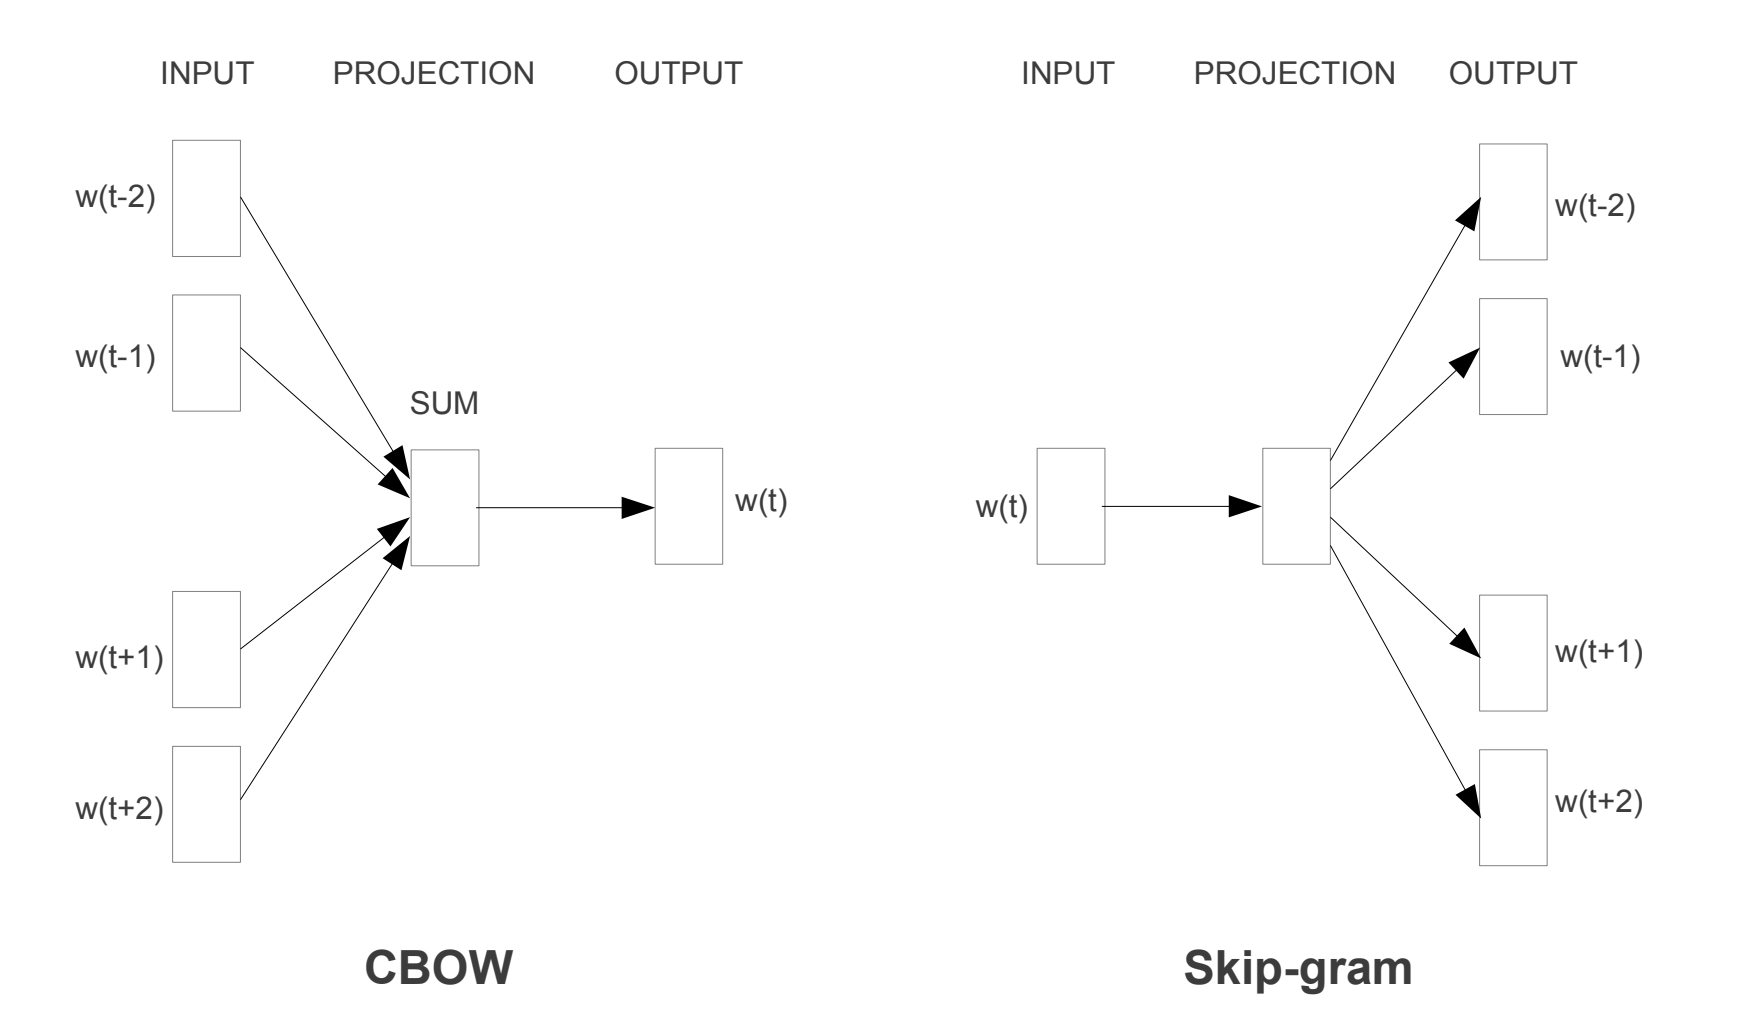
" width="650" height="400"/>

참고: https://arxiv.org/pdf/1301.3781

### CBOW (Continuous bag-of-word model)

> 앞 뒤 문맥을 보고 중심 단어를 유추하는 학습 방식

### Skip-gram

> CBOW와 반대. 중심 단어로 부터 이전 단어와 이후 단어를 유추하는 학습 방식

In [600]:
from konlpy.tag import Mecab
from datasets import load_dataset
from konlpy.tag import Okt

dataset = load_dataset('nsmc', trust_remote_code=True) 
train_dataset = dataset['train']
test_dataset = dataset['test']

x_train = train_dataset['document']
y_train = train_dataset['label']

x_test = test_dataset['document']
y_test = test_dataset['label']

mecab = Mecab()
# 토큰화
def extract_token(word):
    tokens = mecab.morphs(word) 
    return [token for token in tokens if len(token) > 1] # 두 글자 이상

tokenized_corpus = [extract_token(token) for token in x_train[:1500]]

/Users/jihyeokjeong/.anyenv/envs/pyenv/versions/human_lecture/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
from collections import Counter
from itertools import chain

flatten_token = chain.from_iterable(tokenized_corpus)
# 토큰별 빈도수 확인
token_freq = Counter(flatten_token)

In [ ]:
token_freq.most_common(20)

In [ ]:
from gensim.models import Word2Vec

# 모델 학습
model = Word2Vec(
    tokenized_corpus,  # 토큰화된 corpus로 입력값을 넣으면 내부적으로 입력-정답쌍을 만들어 연산을 함 
    vector_size=50,   # 임베딩 벡터 차원
    window=2,          # 좌우 몇개 단어를 문맥으로 볼지 결정 (ex) window=2, skip-gram: 중심 1개 단어로 주변 4개 예측 / CBOW: 주변 4개로 중심 1개 예측 )
    min_count=5,       # 최소 등장 빈도 (1 이상만 학습)
    workers=2,         # 멀티코어 처리 수
    epochs=10,         # 작은 말뭉치 (1 ~ 10만: 10 ~ 20 epochs) / 중간 규모 (100만: 5 ~ 10 epochs) / 대규모 (1000만 이상 3 ~ 5 epochs)
    sg=1              # 1 = Skip-Gram, 0 = CBOW
)

In [ ]:
# 특정 단어의 임베딩 벡터 확인
print(model.wv["감독"]) 

In [ ]:
model.wv.most_similar("영화")

In [ ]:
similarity = model.wv.similarity("영화", "명작") # cosine 유사도 -1에 가까우면 반대 0은 관련 없음 1은 가까움 
print("유사도:", similarity)

In [ ]:
# 모델 저장
model.save("word2vec.model")

# 불러오기
loaded_model = Word2Vec.load("word2vec.model")

In [ ]:
len(model.wv.index_to_key)

### Embedding vector 시각화

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

# 단어 벡터 뽑기
words = list(model.wv.index_to_key)  # 단어 수가 많으면 복잡하므로 50개 정도 추천
vectors = np.array([model.wv[word] for word in words])

# 차원 축소 (3D)
tsne = TSNE(n_components=3, random_state=42, perplexity=10) # n_components는 고차원의 데이터를 몇 차원으로 줄여서 표현할지를 정하는 값 
reduced = tsne.fit_transform(vectors)                      # perplexity는 하나의 점(데이터)이 몇 개의 이웃(주변 점)과 관계를 맺을지를 정하는 값

# 군집화 
kmeans = KMeans(n_clusters=5, random_state=42)
labels = kmeans.fit_predict(reduced) 

# 시각화
colors = ["red", "green", "blue", "orange", "black"]
fig = plt.figure(figsize=(12, 9)) 
ax = fig.add_subplot(111, projection='3d') # nrows, ncols, index

for i, word in enumerate(words):
    x, y, z = reduced[i]
    ax.scatter(x, y, z, c=colors[labels[i]])
    ax.text(x, y, z, word)

ax.set_title("Word Embeddings in 3D (t-SNE)")
plt.show()

In [ ]:
def generate_skipgram(tokens, window=1):
    pairs = []
    for i in range(len(tokens)):
        for w in range(-window, window + 1):
            print(i, w)
            if w == 0 or i + w < 0 or i + w >= len(tokens):
                continue
            pairs.append((tokens[i], tokens[i + w]))
    return pairs

In [ ]:
generate_skipgram(['나는', '어제','밥을','먹었습니다'])

skip-gram

In [ ]:
vocab = ['나는', '오늘', '밥을', '먹었다']
word_to_idx = {'나는': 0, '오늘': 1, '밥을': 2, '먹었다': 3}
vocab_size = 4

나는 -> [1, 0, 0, 0]
오늘 -> [0, 1, 0, 0]
밥을 -> [0, 0, 1, 0]
먹었다 -> [0, 0, 0, 1] 

X = [ [0, 0, 1, 0],  [0, 0, 1, 0] ]  # 중심 단어 '밥을' (두 번)
Y = [ [0, 1, 0, 0],  [0, 0, 0, 1] ]  # 주변 단어 '오늘', '먹었다'

In [ ]:
Input (one-hot) [0, 0, 1, 0]  ← 중심 단어 '밥을'

→ Linear Layer 1 (W1): [vocab_size x embedding_dim]  
→ 은닉층 벡터 (예: [0.5, -0.2, 0.1])

→ Linear Layer 2 (W2): [embedding_dim x vocab_size]  
→ Output 점수 → Softmax → 예측 확률

[0.01, 0.80, 0.05, 0.14]  ← 가장 높은 확률: '오늘'

## PyTorch로 구현하기

In [ ]:
from konlpy.tag import Mecab
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import random
from itertools import chain
from itertools import product

# 샘플 문장
corpus = [
    "영화가 정말 재미 없다",
    "스토리가 너무 지루했다",
    "연기는 좋았다",
    "최악의 영화 였다",
    "음악이 분위기를 살렸다",
    "배우 캐스팅이 최고다"
]

class SkipGramDataset(Dataset):
    def __init__(self, corpus, window_size=2):
        self.tokenized_corpus = self.tokenizer(corpus)
        self.vocab = set(chain.from_iterable(self.tokenized_corpus))
        self.word2idx = {word: idx for idx, word in enumerate(self.vocab)}
        self.window_size = window_size
        self.pairs = self.generate_pair_data(self.tokenized_corpus)

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        center, context = self.pairs[idx]
        return torch.tensor(center, dtype=torch.long), torch.tensor(context, dtype=torch.long)
    
    def tokenizer(self, corpus):
        tokens_list = []
        for document in corpus: 
            tokens = mecab.morphs(document)
            tokens_list.append([token for token in tokens if len(token) > 1]) 
        return tokens_list
    
    def generate_pair_data(self, tokenized_corpus):
        pairs = []

        for tokens in tokenized_corpus:  # 문장 단위
            # 문장의 토큰들을 숫자로 변환 
            indices = [self.word2idx[word] for word in tokens if word in self.word2idx]

            for i, center_word in enumerate(indices):  # 단어 단위
                # 윈도우 범위 설정
                start = max(0, i - self.window_size)
                end = min(len(indices), i + self.window_size + 1)

                # 중심 단어 제외한 주변 단어들
                context_words = [indices[j] for j in range(start, end) if j != i]

                # 중심 단어 × 주변 단어 조합
                pairs += list(product([center_word], context_words))

        return pairs

In [146]:
train_dataset = SkipGramDataset(corpus[:4])
valid_dataset = SkipGramDataset(corpus[4:])
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=2, shuffle=False)

In [ ]:
test_corpus = torch.tensor([1, 2]) # ex) "영화", "정말"
embed = nn.Embedding(6, 3)

In [87]:
em = embed(test_corpus)

In [88]:
em.shape

torch.Size([2, 3])

In [90]:
# 3. Skip-gram 모델
class SkipGram(nn.Module):
    def __init__(self, vocab_size, embed_dim):
        super().__init__()
        self.in_embed = nn.Embedding(vocab_size, embed_dim)
        self.out_embed = nn.Embedding(vocab_size, embed_dim)

    def forward(self, center, context):
        center_vec = self.in_embed(center)   # (batch, dim)
        context_vec = self.out_embed(context)  # (batch, dim)
        score = (center_vec * context_vec).sum(dim=1)  # (batch,) / 두 단어가 연관성이 있는지 판단 -> 내적 연산 (원소 곱 -> 합)
        return score

# 4. 학습 준비
model = SkipGram(vocab_size=len(train_dataset.vocab), embed_dim=4)
optimizer = optim.Adam(model.parameters(), lr=0.01)

def loss_fn(score):
    return -torch.log(torch.sigmoid(score)).mean() # score가 높으면 loss는 낮아지도록 

# 5. 학습
for epoch in range(50):
    total_loss = 0
    for center, context in train_loader:
        optimizer.zero_grad()
        scores = model(center, context)              # (batch,)
        loss = loss_fn(scores)  # Skip-gram 손실
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")

Epoch 1, Loss: 6.6018
Epoch 2, Loss: 6.1567
Epoch 3, Loss: 5.7925
Epoch 4, Loss: 5.4713
Epoch 5, Loss: 5.1568
Epoch 6, Loss: 4.8579
Epoch 7, Loss: 4.5864
Epoch 8, Loss: 4.2980
Epoch 9, Loss: 4.0340
Epoch 10, Loss: 3.7523
Epoch 11, Loss: 3.5138
Epoch 12, Loss: 3.2715
Epoch 13, Loss: 3.0694
Epoch 14, Loss: 2.8117
Epoch 15, Loss: 2.5989
Epoch 16, Loss: 2.4000
Epoch 17, Loss: 2.2058
Epoch 18, Loss: 2.0316
Epoch 19, Loss: 1.8653
Epoch 20, Loss: 1.7050
Epoch 21, Loss: 1.5552
Epoch 22, Loss: 1.4196
Epoch 23, Loss: 1.3070
Epoch 24, Loss: 1.1775
Epoch 25, Loss: 1.0813
Epoch 26, Loss: 0.9831
Epoch 27, Loss: 0.9092
Epoch 28, Loss: 0.8222
Epoch 29, Loss: 0.7585
Epoch 30, Loss: 0.6976
Epoch 31, Loss: 0.6373
Epoch 32, Loss: 0.5891
Epoch 33, Loss: 0.5455
Epoch 34, Loss: 0.5047
Epoch 35, Loss: 0.4712
Epoch 36, Loss: 0.4356
Epoch 37, Loss: 0.4043
Epoch 38, Loss: 0.3818
Epoch 39, Loss: 0.3574
Epoch 40, Loss: 0.3330
Epoch 41, Loss: 0.3133
Epoch 42, Loss: 0.2976
Epoch 43, Loss: 0.2782
Epoch 44, Loss: 0.26

In [92]:
import torch.nn.functional as F

def get_similar_words(query_word, model, word2idx, idx2word, top_k=5):
    if query_word not in word2idx:
        print(f"{query_word} 단어는 vocabulary에 없습니다.")
        return
    
    # 임베딩 벡터로 변환 
    query_idx = word2idx[query_word]
    query_vec = model.in_embed(torch.tensor(query_idx))  # (embed_dim,)

    # 모든 임베딩과 코사인 유사도 계산
    all_embeds = model.in_embed.weight  # (vocab_size, embed_dim)
    similarities = F.cosine_similarity(query_vec.unsqueeze(0), all_embeds)  # (vocab_size,)

    # 가장 유사한 단어 top_k 추출
    topk = torch.topk(similarities, top_k + 1) # 자기 자신도 포함되어 있기 때문에 1 추가 
    for i in range(1, top_k + 1):  # 0번은 자기 자신이므로 skip
        idx = topk.indices[i].item()
        print(f"{idx2word[idx]} ({similarities[idx].item():.4f})")

In [93]:
# 같은 문맥에서 자주 등장하는 단어들의 벡터를 비슷하게 만들어주는 것
get_similar_words("영화", model, train_dataset.word2idx, {v: k for k, v in train_dataset.word2idx.items()})

스토리 (0.7598)
지루 (0.6845)
최악 (0.4579)
정말 (0.3035)
재미 (0.2115)


CBOW

In [ ]:
'오늘'     → [0, 1, 0, 0]  
'먹었다'   → [0, 0, 0, 1]

# 단순히 더하면 → [0, 1, 0, 0] + [0, 0, 0, 1] = [0, 1, 0, 1]
# 평균 내면 → [0, 0.5, 0, 0.5]

'밥을' = [0, 0, 1, 0] 

문맥 단어 수는 window 크기뿐 아니라,
문장의 길이나 위치에 따라 달라질 수 있어요.
예를 들어 문장 맨 앞에 있는 단어는 앞쪽 문맥이 없죠.
그래서 우리는 문맥 단어를 평균 내서
문맥 수가 달라도 입력의 스케일을 일정하게 유지하게 해줍니다

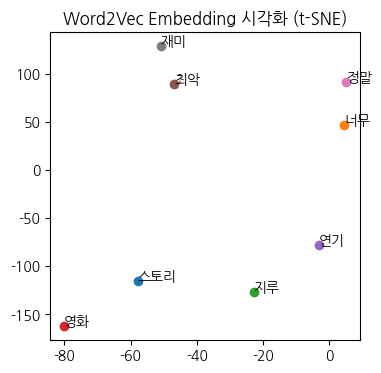

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# 1. 단어 벡터 일부 가져오기
embeds = model.in_embed.weight.detach().numpy()
words = {v: k for k, v in train_dataset.word2idx.items()}

# 2. 차원 축소 (embed_dim → 2D)
tsne = TSNE(n_components=2, perplexity=3)
reduced_embeds = tsne.fit_transform(embeds)

# 3. 시각화
plt.figure(figsize=(4, 4))
for i in range(8):
    plt.scatter(reduced_embeds[i, 0], reduced_embeds[i, 1])
    plt.annotate(words[i], (reduced[i, 0], reduced[i, 1]))
plt.title("Word2Vec Embedding 시각화 (t-SNE)")
plt.show()

### 🧩 Quiz 3

## <a id='four'>4️⃣ 순환 신경망</a><br>

<a href="#lecture_index">
    <span>⬆ 목차로</span>
</a>

## RNN (Recurrent Neural Network)

> RNN은 시계열, 문장, 음성 등 시퀀스 데이터(순서가 있는 데이터)를 처리하는 신경망 구조 <br> 
> 시간의 흐름에 따라 이전의 상태를 기억하며 정보를 반영함 <br> 
> 💡 "이전 시점의 출력을 현재의 입력과 함께 사용하여 현재의 출력을 만든다"

### ✅ RNN 모델 특징

#### ① 시퀀스 데이터 처리에 최적화 
- 입력의 순서 정보를 반영하는 구조 

#### ② 반복 구조 
- 하나의 RNN 셀을 시간 순서대로 반복하여 사용

#### ③ 파라미터 공유 
- 입력 시퀀스의 길이가 달라도 같은 파라미터를 사용하여 연산 

#### ④ 이전 정보 기억 유지 
- 이전 시점의 은닉 상태를 다음 시점 계산에 사용  

#### ⑤ 기울기 소실 문제 
- tanh 활성화 함수의 좁은 출력 범위
- 순환 구조로 인해 시간이 늘어날 수록 곱셈이 길어지는 문제 
- 과거에 중요한 정보를 기억하지 못하는 장기 의존성 문제가 발생함

#### ⑥ BPTT 
- 시간의 흐름에 따라 역전파를 수행하는 방식 
- 여러 시점의 데이터가 같은 가중치를 반복적으로 사용하기 때문에 각 시점의 미분 값을 누적하여 업데이트 함 
- 시퀀스가 일어질 수록 미분값이 점점 작아져 기울기 소실 문제에 취약함 
- 전체 시퀀스를 한 번에 처리 한 후 역전파를 수행하므로 순서를 학습 할 수 있음 

#### ⑦ 다양한 입/출력 구조 
- One to One 🧐 (의미 없음)
- Many to One ✅ 
- Many to Many (동일한 길이) ✅

⚠️ RNN 연산 시 입력 길이와 출력 길이는 항상 같다 

### RNN으로 해결 할 수 있는 문제들

입출력 구조|문제 유형|예시 입력|예시 출력|활용 사례
---|---|---|---|---
Many-to-One|시퀀스 분류|"시간 가는줄 모르고 봤습니다"|긍정/부정|감정분석, 뉴스 주제 분류, 스팸 분류
Many-to-One|시계열 예측|[30, 34, 35](3일간의 주식가격)|37|주식/날씨/신호 예측
Many-to-One|키워드 예측|"구글, 동영상 생성AI '비오2' 출시..."|AI|키워드 추출, 카테고리 분류
Maony-to-Many|시퀀스 라벨링|"충격! 정부가 드디어 발표한 내용은?"|[1, 1, 0, 0, 0, 0]|clickbait 단어 감지, 어조 변화 감지

### 사람이 문장을 이해하는 과정

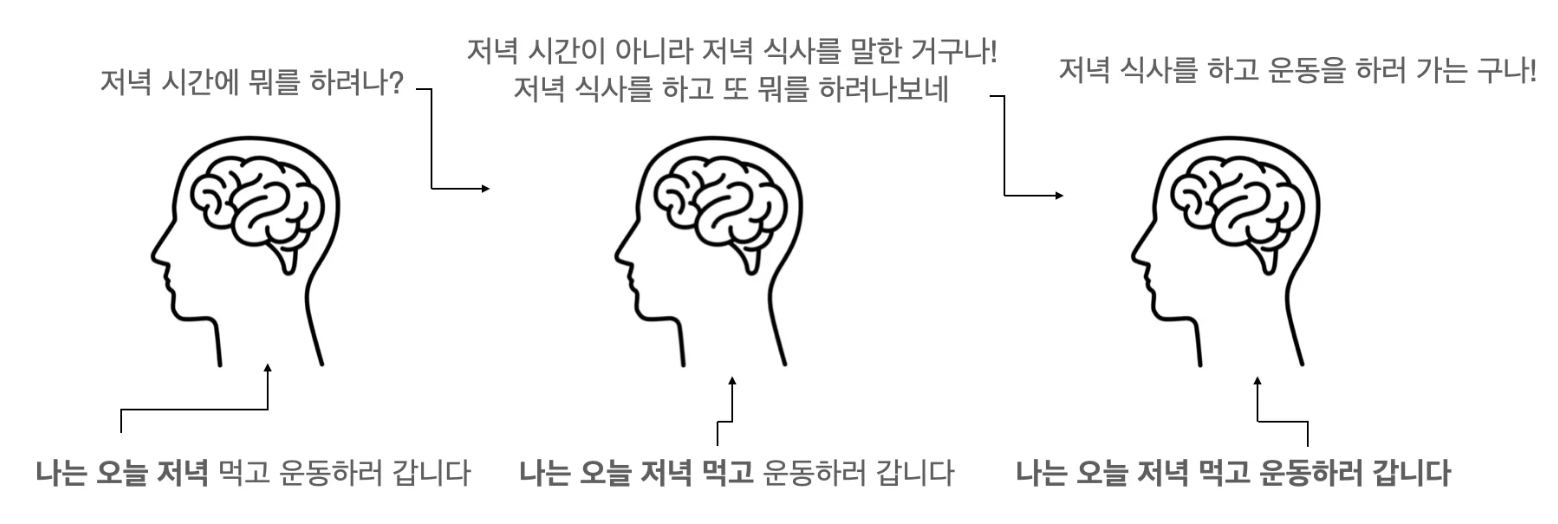

출처: https://aiheroes.ai/community/71

### RNN 구조 수식 및 시각화 

RNN은 입력 시퀀스를 처리할 때, **이전 상태(hidden state)**를 다음 입력과 함께 사용함

- 은닉 상태 수식:
  $$ h_t = \tanh(W_{h}h_{t-1} + W_{x}x_t + b) $$
- 출력 수식:
  $$ y_t = W_{y} h_t + b $$


✅ x_t: t 시점의 입력 시퀀스 데이터 <br>
✅ h_t-1: t-1 시점까지의 상태 데이터. 즉, 이전 까지의 입력 시퀀스가 담고 있던 의미나 패턴을 압축하여 표현한 벡터 <br>
✅ W_h: 이전 시점까지의 은닉 상태 가중치. 이전 까지의 입력 시퀀스가 현재 상태에 얼마나 영향을 줄지 결정하는 가중치 행렬 <br>
✅ W_x: 현재 시점의 은닉 상태 가중치. 현재 시점의 입력 시퀀스가 현재 상태에 얼마나 영향을 줄지 결정하는 가중치 행렬 <br>
✅ b: 바이어스. 입력과 과거 상태가 모두 0일 때도 일정한 출력을 유도할 수 있도록 도와주는 편향 벡터 

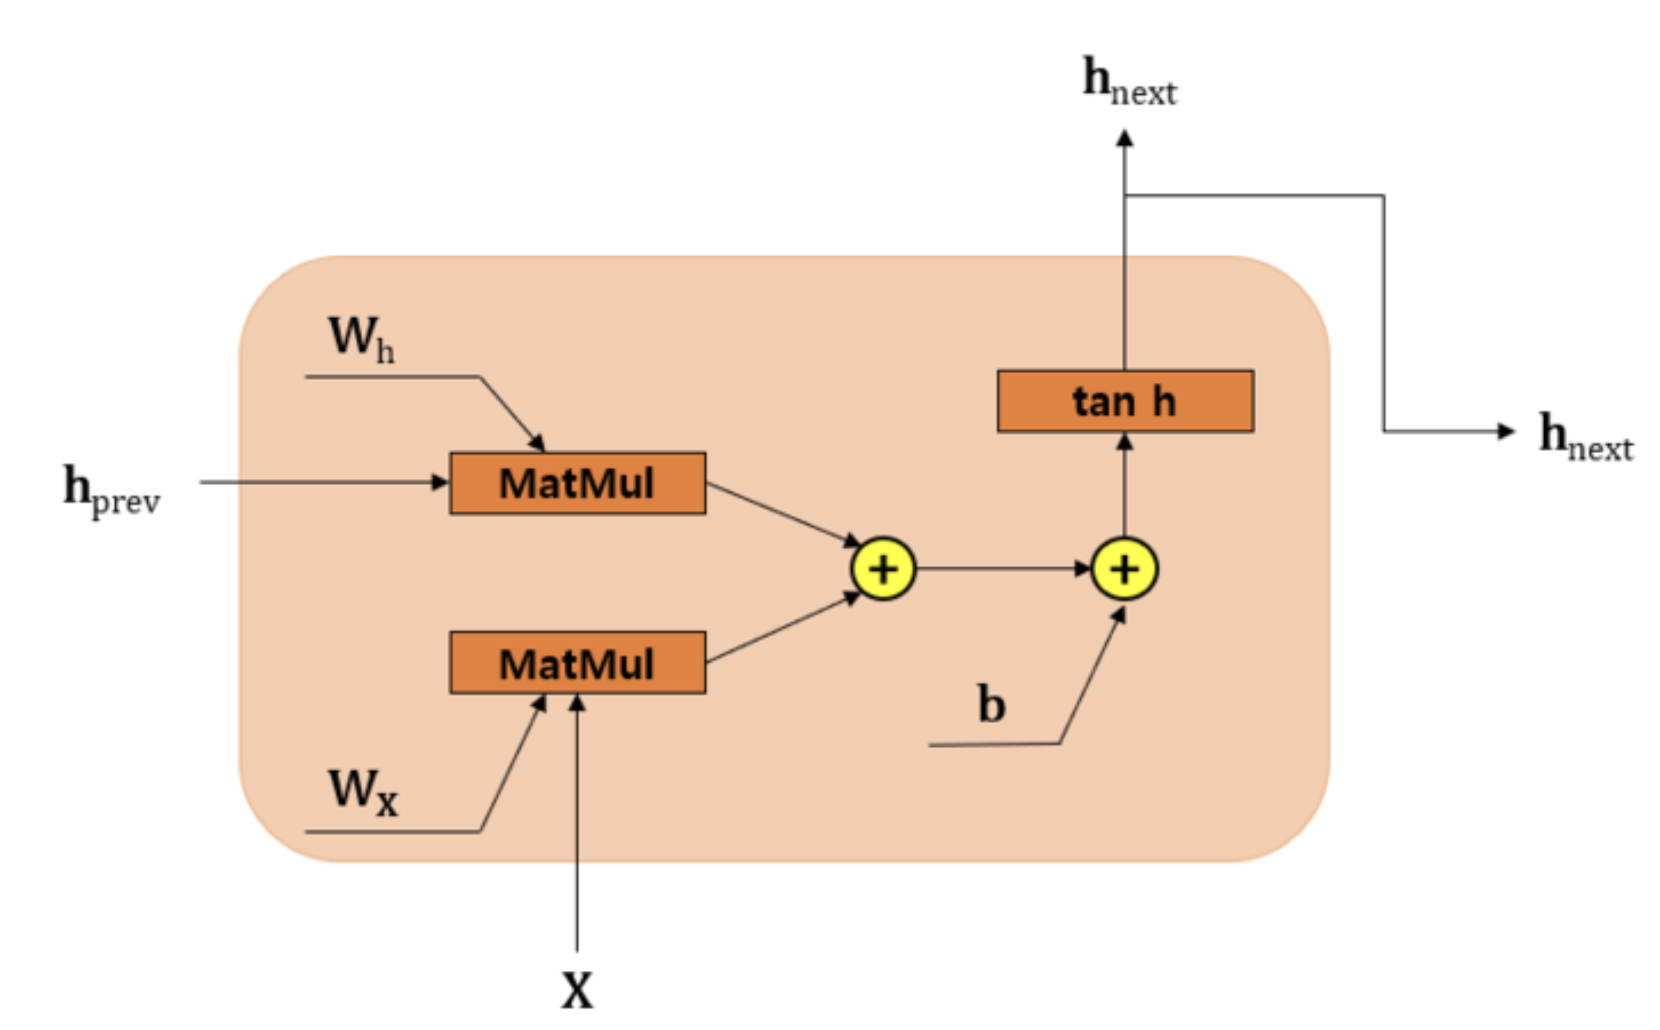

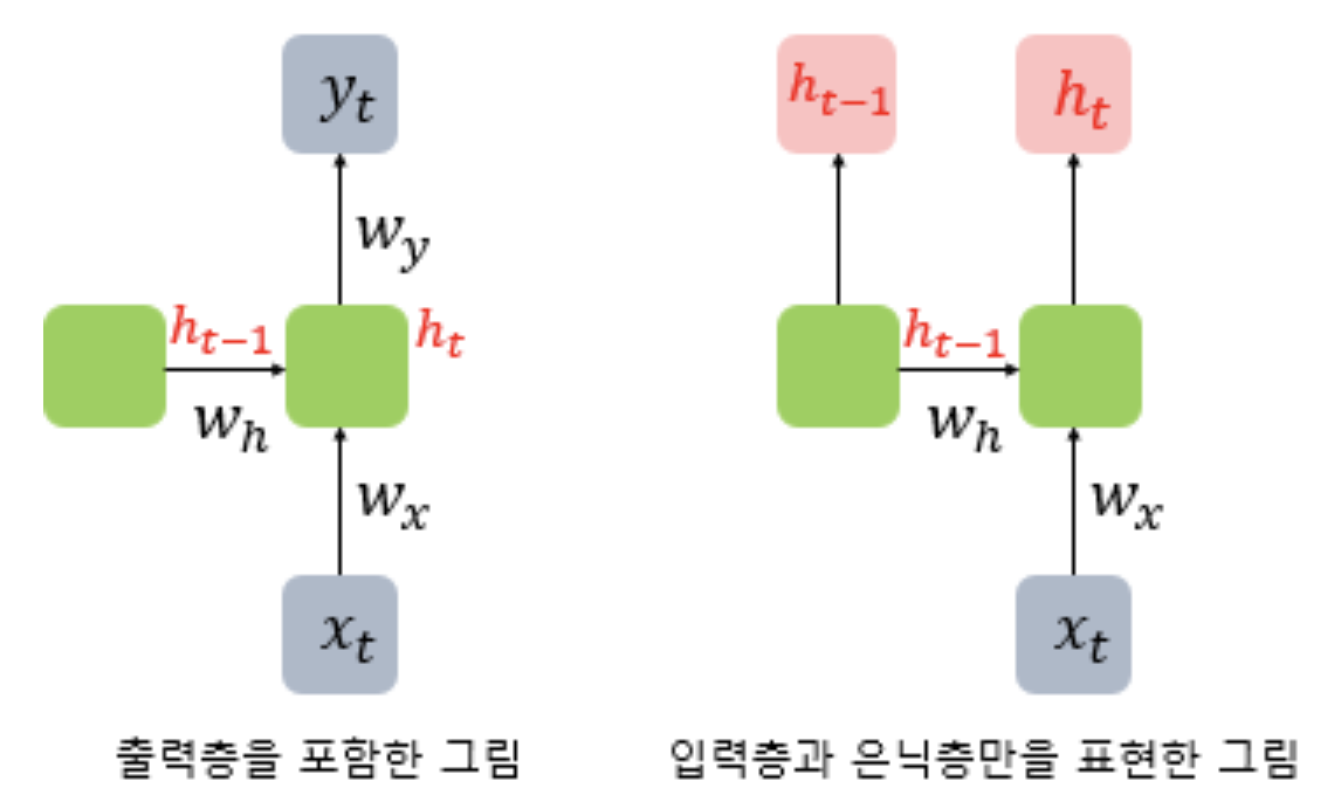

출처1: https://wikidocs.net/22886 <br>
출처2: https://sooftware.io/rnn/

### Numpy를 활용하여 쉽게 이해하기

In [11]:
import numpy as np

def rnn_step(x_t, h_prev, W_x=0.5, W_h=0.5, b=0):
    h_t = np.tanh(W_x * x_t + W_h * h_prev + b)
    return h_t

inputs = range(-10, 10, 1)
h = 0  # 초기 상태

print("시간  | 입력 xₜ | 이전 hₜ₋₁ | 현재 hₜ")
print("-------------------------------")
for t, x in enumerate(inputs):
    h_new = rnn_step(x, h)
    print(f"{t:4}  | {x:7} | {h:9.4f} | {h_new:8.4f}")
    h = h_new

시간  | 입력 xₜ | 이전 hₜ₋₁ | 현재 hₜ
-------------------------------
   0  |     -10 |    0.0000 |  -0.9999
   1  |      -9 |   -0.9999 |  -0.9999
   2  |      -8 |   -0.9999 |  -0.9998
   3  |      -7 |   -0.9998 |  -0.9993
   4  |      -6 |   -0.9993 |  -0.9982
   5  |      -5 |   -0.9982 |  -0.9950
   6  |      -4 |   -0.9950 |  -0.9865
   7  |      -3 |   -0.9865 |  -0.9635
   8  |      -2 |   -0.9635 |  -0.9018
   9  |      -1 |   -0.9018 |  -0.7402
  10  |       0 |   -0.7402 |  -0.3541
  11  |       1 |   -0.3541 |   0.3122
  12  |       2 |    0.3122 |   0.8198
  13  |       3 |    0.8198 |   0.9571
  14  |       4 |    0.9571 |   0.9860
  15  |       5 |    0.9860 |   0.9950
  16  |       6 |    0.9950 |   0.9982
  17  |       7 |    0.9982 |   0.9993
  18  |       8 |    0.9993 |   0.9998
  19  |       9 |    0.9998 |   0.9999


In [16]:
import numpy as np

def rnn_step(x_t, h_prev, W_x, W_h, b):
    return np.tanh(np.dot(W_x, x_t) + np.dot(W_h, h_prev) + b)

# 파라미터: 동일 (공유됨)
W_x = np.array([[0.5, -0.2]])  # (1, 2)
W_h = np.array([[0.8]])        # (1, 1)
b = np.array([0.1])            # (1,)

# 문장 1: "나는 사람이다"
# → ["나는", "사람이다"]
# → 각 토큰을 2차원 임베딩 벡터로 표현
sentence1 = [
    np.array([0.9, 0.1]),   # "나는"
    np.array([0.2, 0.8])    # "사람이다"
]

# 문장 2: "나는 재미 있는 사람이다"
# → ["나는", "재미", "있는", "사람이다"]
sentence2 = [
    np.array([0.9, 0.1]),   # "나는"
    np.array([0.4, 0.3]),   # "재미"
    np.array([0.2, 0.2]),   # "있는"
    np.array([0.2, 0.8])    # "사람이다"
]

def run_rnn_sequence(sequence, label):
    h = np.array([0.0])  # 초기 은닉 상태
    print(f"\n▶ 문장: {label} (길이={len(sequence)})")
    for i, x in enumerate(sequence):
        h = rnn_step(x, h, W_x, W_h, b)
        print(f"  Step {i+1}: input={x} → hidden={h[0]:.4f}")
    print(f"  🔹 최종 문장 벡터(h): {h[0]:.4f}")

run_rnn_sequence(sentence1, "나는 사람이다")
run_rnn_sequence(sentence2, "나는 재미 있는 사람이다")


▶ 문장: 나는 사람이다 (길이=2)
  Step 1: input=[0.9 0.1] → hidden=0.4854
  Step 2: input=[0.2 0.8] → hidden=0.4039
  🔹 최종 문장 벡터(h): 0.4039

▶ 문장: 나는 재미 있는 사람이다 (길이=4)
  Step 1: input=[0.9 0.1] → hidden=0.4854
  Step 2: input=[0.4 0.3] → hidden=0.5569
  Step 3: input=[0.2 0.2] → hidden=0.5410
  Step 4: input=[0.2 0.8] → hidden=0.4404
  🔹 최종 문장 벡터(h): 0.4404


### BPTT (Backpropagation Through Time)

> BPTT는 일반 신경망과는 달리 layer 별로 미분값(gradient)을 구해서 연산하지 않고, <br>
> 하나의 RNN 셀의 연산을 시간축으로 펼쳐서 미분값(gradient)을 구하여 같은 가중치에 누적반영 하는 시간 기반의 역전파 방식 

🛠️ leaf tensor: 학습 가능한 텐서. (requires_grad=True 이고, 연산을 통해 만들어지지 않는 텐서)

$$
\begin{align}
h_t &= \tanh(W x_t + U h_{t-1}) \\
y_t &= V h_t \\
L &= \sum_{t=1}^{T} \ell(y_t, target_t)
\end{align}
$$ 

$$
\begin{aligned}
\frac{\partial L}{\partial W} &= \sum_{t=1}^{T} \frac{\partial L_t}{\partial y_t} \cdot \frac{\partial y_t}{\partial h_t} \cdot \frac{\partial h_t}{\partial W} \\
\frac{\partial L}{\partial U} &= \sum_{t=1}^{T} \frac{\partial L_t}{\partial y_t} \cdot \frac{\partial y_t}{\partial h_t} \cdot \frac{\partial h_t}{\partial h_{t-1}} \cdot \frac{\partial h_{t-1}}{\partial U} \\
\frac{\partial L}{\partial V} &= \sum_{t=1}^{T} \frac{\partial L_t}{\partial y_t} \cdot \frac{\partial y_t}{\partial V}
\end{aligned}
$$

$$
\begin{aligned}
W &\leftarrow W - \eta \cdot \frac{\partial L}{\partial W} \\
U &\leftarrow U - \eta \cdot \frac{\partial L}{\partial U} \\
V &\leftarrow V - \eta \cdot \frac{\partial L}{\partial V}
\end{aligned}
$$

✅ W: 현재 상태를 반영하는 가중치 <br> 
✅ U: 이전 상태(기억)을 얼마나 반영할지를 조절하는 가중치 <br>
✅ V: 출력값으로 변환하기 위한 가중치 <br>
✅ η: 학습률


### backward vs retain grad with backward

> 학습가능한 파라미터만 미분값을 저장하며 학습하는 방식 vs 중간 결과값 같이 저장하며 학습하는 방식

### backward

In [538]:
import torch

In [ ]:
W1 = torch.tensor([1.0], requires_grad=True) # leaf tensor 
optimizer = torch.optim.SGD([W1], lr=0.001)

In [540]:
optimizer.zero_grad()

x = torch.tensor([2.0], requires_grad=False) 
target = torch.tensor([25.0], requires_grad=False)  

z = W1*x + 1 # 1x2+ 1 = 3 
y = z ** 2  # 3x3 = 9

loss = (target - y)**2  # (25 - 9)**2 = 256  

loss.backward()           

In [541]:
# loss 미분 (dL/dy) -> 2x(y-target) = 2*(9-25) = -32 
# y 미분 (dy/dz) -> 2xz = 2*3 = 6 
# z 미분 (dz/dw1) -> x = 2  
# x 미분 (dz/dx) -> w1 = 1  

# dL/dy -> dL/dy = -32 
# dL/dz -> dL/dy * dy/dz = -32*6 = -192
# dL/dw1 -> dL/dy * dy/dz * dz/dw1 = -32*6*2 = -384           
# dL/dx -> dL/dy * dy/dz * dz/dx = -32*6*1 = -192

loss.grad, y.grad, z.grad, W1.grad, x.grad

/var/folders/yy/pb8s0nd506g_wpnllg87m4_w0000gn/T/ipykernel_39157/821740174.py:11: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:494.)
  loss.grad, y.grad, z.grad, W1.grad, x.grad


(None, None, None, tensor([-384.]), None)

In [368]:
# 가중치 업데이트
optimizer.step()

In [369]:
W1

tensor([1.7096], requires_grad=True)

### retain grad with backward

In [569]:
W1 = torch.tensor([1.0], requires_grad=True) # leaf tensor 
optimizer = torch.optim.SGD([W1], lr=0.0001)

In [ ]:
xs = [torch.tensor([1.0], requires_grad=False), torch.tensor([2.0], requires_grad=False), torch.tensor([3.0], requires_grad=False)] 
targets = [torch.tensor([9.0], requires_grad=False), torch.tensor([25.0], requires_grad=False), torch.tensor([49.0], requires_grad=False)]  

loss_total = 0
zs, ys, losses = [], [], []

for x, target in zip(xs, targets):
    optimizer.zero_grad()
    z = W1 * x + 1          # 중간 출력
    z.retain_grad()
    y = z ** 2              # 최종 출력
    y.retain_grad()
    loss = (target - y) ** 2
    loss.retain_grad()

    zs.append(z)
    ys.append(y)
    losses.append(loss)
    
    # loss.backward()
    
    loss_total += loss    

loss_total.backward(retain_graph=True)   
optimizer.step()     

In [571]:
W1.grad # dL/w11 + dL/w12 + dL/w13 -> 모든 미분 값 합산 

tensor([-2008.])

In [572]:
W1

tensor([1.2008], requires_grad=True)

### 💡 합산된 미분 값으로 가중치를 초기화 하는 이유는? 

- 평균을 내면 전체 맥락이 반영이 제대로 안될 수 있음 
- 누적으로 하면 흐름의 극적인 전환도 반영이 가능해짐 
- 예) 하루 기분, 계좌 잔고 

### Truncated BPTT

> 시퀀스가 길어질 때 발생하는 기울기 소실 문제나 학습 비효율 문제를 줄이기 위해, <br>
> 전체 시퀀스를 일정한 길이로 잘라서 구간 단위로 BPTT를 수행하는 방법 

### 🧩 Quiz 4

### RNN에서는 BPTT를 사용하는 이유가 무엇인가요?

- 시퀀스 데이터이 시간적 연속성을 충분히 학습하기 위해서
- 기술적으로 하나의 셀을 시간축을 따라 반복적으로 사용하기 때문에, 각 시점에서 발생하는 오차가 공유된 가중치에 고루 반영하기 위해. 중간 시점에서 연산된 결과는 따로 지정해주지 않으면 저장하지 않기 때문에 BPTT를 할때는 중간 결과를 저장하여 데이터의 연속성을 학습 할 수 있도록 계산 해야 하기 때문.

### RNN과 ResNet의 공통점과 차이점을 각각 서술하시오.

#### [공통점]

- 정보를 유지하고 전달하는 구조 
- 이전 결과를 현재 연산에 직접 연결해서 “정보가 사라지지 않도록” 보존

#### [차이점]

- [가중치] 시간의 축을 따라 가중치를 공유한다 / 가중치를 공유하지 않음 
- [블록 구조] 하나의 셀을 여러 시점에 반복 사용 / 비슷한 블록을 반복적으로 사용하지만 각각 독립적 

### 논문 출처

출처: https://arxiv.org/pdf/1808.03314

### PyTorch로 구현하기

#### RNN 레이어 없이 직접 구현하기

In [219]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. 단어 사전
vocab = {0: "나는", 1: "배고프다", 2: "너는", 3: "피곤하다"}
x_train = torch.tensor([
    [0, 1],  # "나는 배고프다" → 0
    [2, 3]   # "너는 피곤하다" → 1
])

y_train = torch.tensor([0, 1])  # (batch,)

In [ ]:
class SimpleRNN(nn.Module): 
    def __init__(self, vocab_size, embedding_dim, hidden_size, output_size):
        super(SimpleRNN, self).__init__()
        # batch size, embedding_dim
        self.embedding = nn.Embedding(vocab_size, embedding_dim) # (Batch, Embed(feature))

        # 출력 차원 수 x 입력 차원 수
        # 문장의 순서와 문맥을 이해하는 과정 + 요약된 정보를 만들어냄 
        self.W_x = nn.Parameter(torch.randn(hidden_size, embedding_dim)) # (Hidden, Embed(feature)) -> Hidden은 결국 출력될 차원이라고 생각해도됨 -> 시퀀스를 따라 기억하고 출력해낼 내부 상태 크기 RNN이 표현할 수 있는 정보 용량
        self.W_h = nn.Parameter(torch.randn(hidden_size, hidden_size)) # (Hidden, Hidden)
        self.b = nn.Parameter(torch.randn(hidden_size)) # (Hidden, )

        # 요약된 정보를 바탕으로 원하는 출력으로 의미를 연결
        self.W_y = nn.Parameter(torch.randn(output_size, hidden_size)) # (Out, Hidden)
        self.b_y = nn.Parameter(torch.randn(output_size)) # (Out, )

        self.hidden_size = hidden_size
    
    # RNN 셀 (한 시점)
    def rnn_step(self, x_t, h_prev):
        # x_t: (B, E), h_prev: (B, H)
        h_t = torch.tanh(
            torch.matmul(x_t, self.W_x.T) +     # (B, E) @ (E, H) -> (B, H)
            torch.matmul(h_prev, self.W_h.T) +  # (B, H) @ (H, H) -> (B, H)
            self.b                              # (H,) -> broadcast
        )
        return h_t

    # 문장 전체 순회
    def forward(self, sentence_indices):
        # sentence_indices: (B, T)
        embedded = self.embedding(sentence_indices)  # (B, T, E)

        batch_size, seq_len, _ = embedded.shape
        h = torch.zeros(batch_size, self.hidden_size, device=embedded.device)  # (B, H)

        for t in range(seq_len):
            x_t = embedded[:, t, :]  # (B, E)
            h = self.rnn_step(x_t, h) 

        y = torch.matmul(h, self.W_y.T) + self.b_y  # (B, H) @ (H, O)  -> (B, O)
        return y

In [221]:
model = SimpleRNN(vocab_size=len(vocab), embedding_dim=3, hidden_size=5, output_size=2)
optimizer = optim.SGD(model.parameters(), lr=0.05)
criterion = nn.CrossEntropyLoss()

# 학습
epochs = 20
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    outputs = model(x_train)              # (B, C)
    loss = criterion(outputs, y_train)   # CrossEntropyLoss는 (B, C) vs (B,) 비교
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0 or epoch == 0:
        pred = torch.argmax(outputs, dim=1)
        acc = (pred == y_train).float().mean()
        print(f"[{epoch+1:3d}] loss: {loss.item():.4f}, acc: {acc.item():.2f}")

[  1] loss: 0.7334, acc: 0.50
[ 10] loss: 0.1186, acc: 1.00
[ 20] loss: 0.0814, acc: 1.00


#### RNN 레이어를 활용하여 구현하기

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. 단어 사전
vocab = {0: "나는", 1: "배고프다", 2: "너는", 3: "피곤하다"}
x_train = torch.tensor([
    [0, 1],  # "나는 배고프다" → 0
    [2, 3],   # "너는 피곤하다" → 1
    [0, 3]
])

y_train = torch.tensor([0, 1, 1])  # (batch,)

# 1. RNN 기반 분류 모델 정의
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, output_size):
        super(RNNClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        self.rnn = nn.RNN(input_size=embedding_dim,
                          hidden_size=hidden_size,
                          batch_first=True)  # 입력 shape: (B, T, E) / 옵션을 안주면 (T, B, E) 형태로 연산함

        self.fc = nn.Linear(hidden_size, output_size)  # 마지막 hidden → 출력

    def forward(self, x):
        embedded = self.embedding(x)     # (B, T, E)
        output, h_n = self.rnn(embedded) # output: (B, T, H), h_n: (1, B, H) 앞에 1은 layer 수
        final_hidden = h_n.squeeze(0)    # (B, H)
        logits = self.fc(final_hidden)   # (B, O)
        return logits
    
    # rnn shape -> (num_layers * num_directions, batch_size, hidden_size)

# RNN layer의 의미   
# RNN을 레이어로 쌓는다는 건, “앞 레이어의 모든 time step 출력을 다음 레이어의 입력으로 전달한다”는 뜻
# 하나의 시퀀스를 여러 번 “해석”하면서 더 복잡한 패턴을 학습할 수 있도록 RNN 셀을 층층이 쌓아올리는 구조
# 레이어 1: “단어” 단위의 해석
# 레이어 2: “구”나 “문장” 단위의 의미 파악
# 레이어 3: 더 추상적인 의미 (의도, 감정 등)

In [36]:
x_train = torch.tensor([
    [0, 1],  # "나는 배고프다" → 0
    [2, 3],  # "너는 피곤하다" → 1
    [0, 3]
])

In [37]:
x_train

tensor([[0, 1],
        [2, 3],
        [0, 3]])

In [39]:
em = nn.Embedding(4, 5)

In [42]:
em(x_train).shape

torch.Size([3, 2, 5])

In [41]:
em(x_train.T).shape

torch.Size([2, 3, 5])

In [224]:
vocab_size = 4
embedding_dim = 3
hidden_size = 5
output_size = 2

# 4. 모델 정의
model = RNNClassifier(vocab_size, embedding_dim, hidden_size, output_size)

# 5. 손실 함수 및 옵티마이저
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# 6. 학습 루프
epochs = 20
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    outputs = model(x_train)             # (B, C)
    loss = criterion(outputs, y_train)   # (B, ) vs (B, C)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0 or epoch == 0:
        pred = torch.argmax(outputs, dim=1)
        acc = (pred == y_train).float().mean()
        print(f"[{epoch+1:3d}] loss: {loss.item():.4f}, acc: {acc.item():.2f}")

[  1] loss: 0.6446, acc: 0.50
[ 10] loss: 0.4553, acc: 1.00
[ 20] loss: 0.2442, acc: 1.00


### 네이버 영화 리뷰 긍정/부정 분류 

In [227]:
import torch
import torch.nn as nn
import torch.optim as optim
from datasets import load_dataset
from transformers import AutoTokenizer
from torch.utils.data import DataLoader, Dataset

In [228]:
dataset = load_dataset('nsmc', trust_remote_code=True)
tokenizer = AutoTokenizer.from_pretrained('klue/bert-base')

def tokenize_function(example):
    return tokenizer(
        example['document'],
        padding='max_length',
        truncation=True,
        max_length=128
    )

tokenized_datasets = dataset.map(tokenize_function, batched=True)

class NsmcDataset(Dataset):
    def __init__(self, dataset):
        self.input_ids = dataset['input_ids']
        self.attention_mask = dataset['attention_mask']
        self.labels = dataset['label']

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'input_ids': torch.tensor(self.input_ids[idx]),
            'attention_mask': torch.tensor(self.attention_mask[idx]),
            'labels': torch.tensor(self.labels[idx])
        }

Map: 100%|██████████| 50000/50000 [00:02<00:00, 23109.50 examples/s]


In [229]:
train_dataset = NsmcDataset(tokenized_datasets['train'])
test_dataset = NsmcDataset(tokenized_datasets['test'])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [231]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim):
        super(RNNClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, input_ids):
        embedded = self.embedding(input_ids)
        output, hidden = self.rnn(embedded)
        return self.fc(hidden.squeeze(0))

In [232]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = RNNClassifier(
    vocab_size=tokenizer.vocab_size,
    embed_dim=128,
    hidden_dim=256,
    output_dim=2
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
for epoch in range(5):  # 에폭 수는 필요에 따라 조정
    model.train()
    total_loss = 0
    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")

In [ ]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids)
        predictions = torch.argmax(outputs, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Test Accuracy: {correct/total:.4f}")